# 09 - India's long-run climate: warming, winters, monsoon, and what it means for harvests
**Heat, Rain & Harvest.** Phase 10 (extension). Data: IMD gridded daily temperature 1951-2025 (1 deg) and rainfall
1901-2025 (0.25 deg), averaged to the 640 Census-2011 districts with area weights, then to India with district-area
weights. Trends are **Sen's slope per decade** with the **Mann-Kendall** test (robust to outliers, no normality
assumption). Baseline normal: 1951-1980. Methods: DECISIONS D20-D22.

Produced by:
```
python -m src.climate_to_district --vars tmax tmin --start 1951 --end 2025 --tag longrun
python -m src.climate_to_district --vars rain --start 1901 --end 2025 --tag longrun
python -m src.climate_trends && python -m src.monsoon_trends
python -m src.climate_harvest && python -m src.harvest_factors
```

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import PROCESSED, FIGURES
from src.boundaries import load_pc11_districts
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
save = lambda fig, n: fig.savefig(FIGURES / f"{n}.png", bbox_inches="tight", dpi=150)
C = PROCESSED / "climate"; geo = load_pc11_districts()
ann = pd.read_csv(C / "national_annual.csv"); tr = pd.read_csv(C / "national_trends.csv")
sig = lambda p: "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else ""
print(ann.year.min(), "-", ann.year.max(), "|", len(ann), "years")

1951 - 2025 | 75 years


## 1. How fast is India warming? (year, season, month)

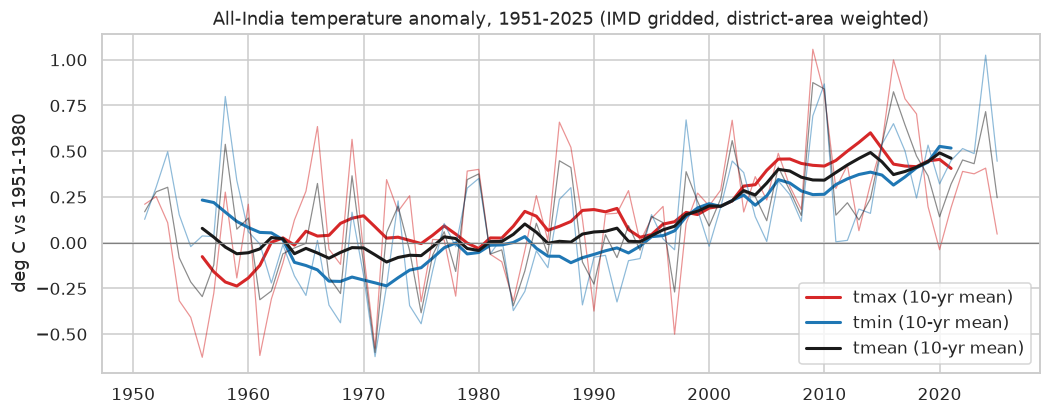

tmax: +0.081 C per decade (Mann-Kendall p=1.3e-05) -> +0.60 C over 1951-2025
tmin: +0.071 C per decade (Mann-Kendall p=7e-05) -> +0.53 C over 1951-2025
tmean: +0.075 C per decade (Mann-Kendall p=9.6e-07) -> +0.56 C over 1951-2025


In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
for v, c in (("tmax", "tab:red"), ("tmin", "tab:blue"), ("tmean", "k")):
    s = ann[f"{v}_anom_vs_1951_80"]
    ax.plot(ann.year, s, c=c, lw=.8, alpha=.5); ax.plot(ann.year, s.rolling(10, center=True).mean(), c=c, lw=2, label=f"{v} (10-yr mean)")
ax.axhline(0, c="grey", lw=.8); ax.set(ylabel="deg C vs 1951-1980", title="All-India temperature anomaly, 1951-2025 (IMD gridded, district-area weighted)")
ax.legend(); save(fig, "09_india_temperature_anomaly"); plt.show()
a = tr[tr.period == "annual"].set_index("variable")
for v in ("tmax", "tmin", "tmean"):
    r = a.loc[v]; print(f"{v}: {r.sen_per_decade:+.3f} C per decade (Mann-Kendall p={r.mk_p:.2g}) -> {r.sen_per_decade*7.4:+.2f} C over 1951-2025")

**Per day / week / month / year.** A *rate* only makes sense per unit of time over many years, so "how much warmer each
day" is answered as: how much warmer is the *same calendar day* now (1996-2025 normal) than it used to be (1951-1980
normal). The per-decade slope divided by 10 is the per-year rate.

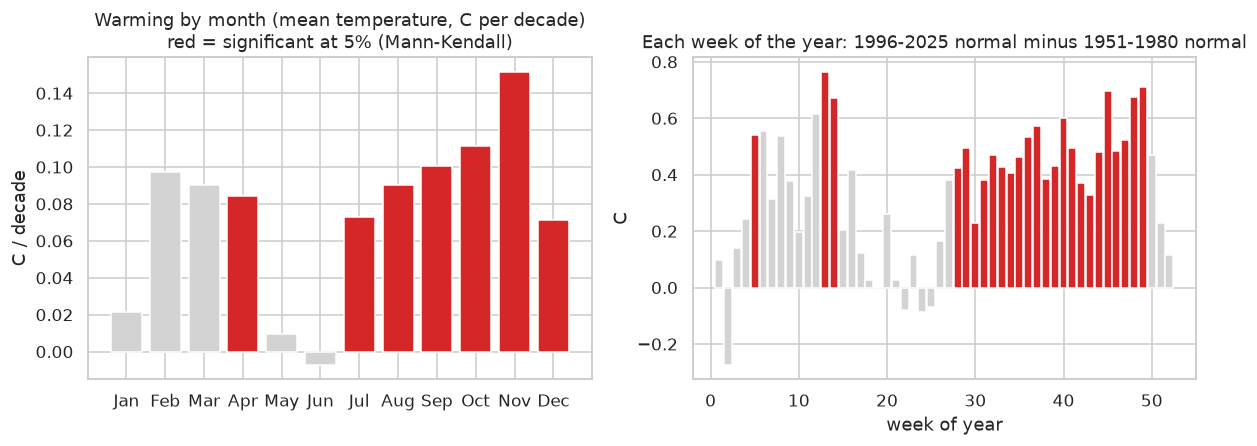

variable,tmax,tmean,tmin,tmean per year,tmean signif.
period,,,,,
annual,0.081,0.075,0.071,0.008,***
Jan,-0.005,0.021,0.051,0.002,
Feb,0.087,0.097,0.099,0.010,
Mar,0.093,0.090,0.088,0.009,
Apr,0.129,0.084,0.047,0.008,*
May,0.026,0.010,0.010,0.001,
Jun,0.016,-0.007,-0.009,-0.001,
Jul,0.090,0.073,0.057,0.007,**
Aug,0.127,0.090,0.065,0.009,***


In [3]:
per = tr[tr.variable == "tmean"].set_index("period")
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
m = per.loc[months]
ax[0].bar(months, m.sen_per_decade, color=["tab:red" if p < .05 else "lightgrey" for p in m.mk_p])
ax[0].set(title="Warming by month (mean temperature, C per decade)\nred = significant at 5% (Mann-Kendall)", ylabel="C / decade")
wk = pd.read_csv(C / "national_week_of_year.csv")
ax[1].bar(wk.week, wk.warming_c, color=["tab:red" if p < .05 else "lightgrey" for p in wk.mk_p], width=.9)
ax[1].set(title="Each week of the year: 1996-2025 normal minus 1951-1980 normal", xlabel="week of year", ylabel="C")
save(fig, "09_warming_by_month_week"); plt.show()
tab = tr.pivot_table(index="period", columns="variable", values="sen_per_decade").loc[["annual"] + months + ["winter (DJF)", "pre-monsoon (MAM)", "monsoon (JJAS)", "post-monsoon (ON)"]]
tab["tmean per year"] = tab.tmean / 10
tab["tmean signif."] = [sig(p) for p in per.loc[tab.index].mk_p]
tab.round(3)

In [4]:
doy = pd.read_csv(C / "national_day_of_year.csv")
print(f"Average calendar day: {doy.warming_c.mean():+.2f} C warmer than in 1951-80; warmest-shift day-of-year range "
      f"{doy.warming_c.min():+.2f} to {doy.warming_c.max():+.2f} C")
print("Record hot years (all-India mean):"); print(pd.read_csv(C / "record_hot_years.csv").round(2).to_string(index=False))
rm = pd.read_csv(C / "record_hot_month_years.csv"); print("\nHottest year for each month:", dict(zip(rm.month, rm.year)))

Average calendar day: +0.35 C warmer than in 1951-80; warmest-shift day-of-year range -0.44 to +0.88 C
Record hot years (all-India mean):
 year  tmean  tmean_anom_vs_1951_80
 2009  25.95                   0.88
 2010  25.92                   0.84
 2016  25.90                   0.82
 2024  25.79                   0.72
 2017  25.72                   0.64
 2002  25.63                   0.56
 2015  25.61                   0.54
 1958  25.61                   0.54
 2018  25.55                   0.47
 2022  25.53                   0.45

Hottest year for each month: {'Jan': 2009, 'Feb': 2006, 'Mar': 2010, 'Apr': 2010, 'May': 2010, 'Jun': 1958, 'Jul': 2002, 'Aug': 2009, 'Sep': 2015, 'Oct': 1951, 'Nov': 1979, 'Dec': 2008}


**What this says.** India's mean temperature is rising by roughly 0.07-0.08 C per decade since 1951 (about
0.5-0.6 C so far), with the fastest and most certain warming after the monsoon (Oct-Nov) and in late summer. May and
June show no clear trend - pre-monsoon heat is very variable year to year. This is a district-average of gridded data,
so it is smaller than single-station trends in cities (which also include urban heat).

### Where is it warming fastest?

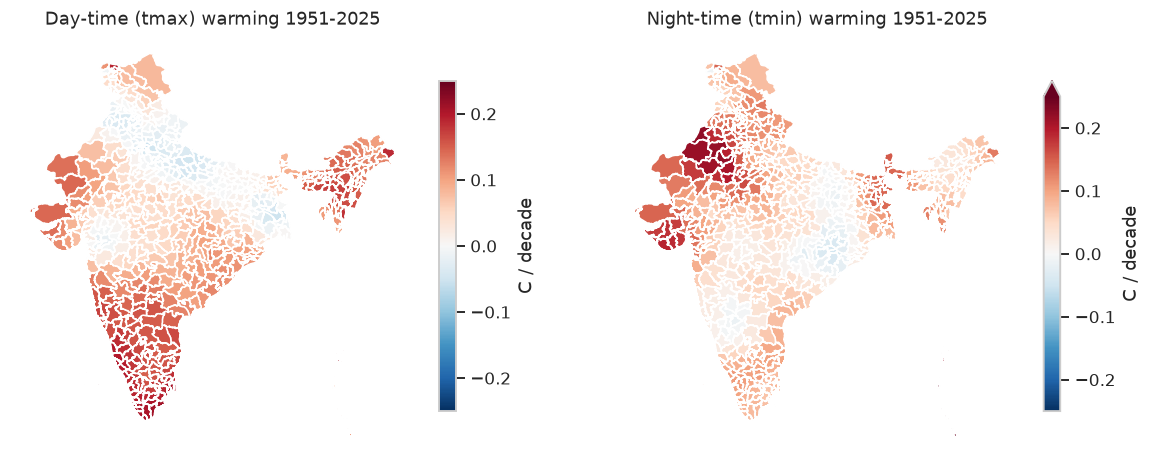

share of districts with significant (p<0.05) mean warming: 69.2 %


In [5]:
dt = pd.read_parquet(C / "district_trends.parquet")
g = geo.merge(dt[dt.period == "annual"], on="district_id")
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
for a, v, t in ((ax[0], "tmax_per_decade", "Day-time (tmax)"), (ax[1], "tmin_per_decade", "Night-time (tmin)")):
    g.plot(column=v, cmap="RdBu_r", vmin=-.25, vmax=.25, legend=True, ax=a, legend_kwds={"shrink": .6, "label": "C / decade"})
    a.set_title(f"{t} warming 1951-2025"); a.axis("off")
save(fig, "09_map_district_warming"); plt.show()
print("share of districts with significant (p<0.05) mean warming:", round((dt[dt.period == 'annual'].tmean_mk_p < .05).mean() * 100, 1), "%")

## 2. Are winters getting shorter and milder? Will they disappear?
**Cool day** (Oct-Mar): a day whose 7-day mean temperature is colder than the district's own coolest quarter of the year
in 1951-1980 (25th percentile of the 7-day mean). **Cold night**: tmin below the district's 1951-1980 Dec-Feb 10th percentile. Counts are averaged over
districts. Winter season labelled by the year it ends.

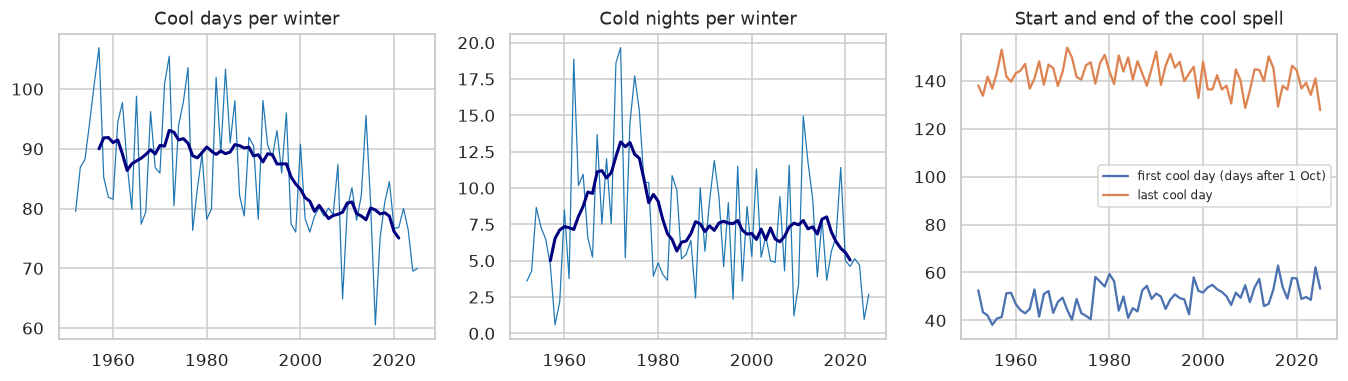

cool_days: -2.09 per decade (p=2.4e-05)
cold_nights: -0.32 per decade (p=0.14)
first_cool_day: +1.25 per decade (p=0.00012)
last_cool_day: -0.62 per decade (p=0.049)
cool days: 89.3 (1952-81) -> 79.3 (1996-2025), -11%


In [6]:
w = pd.read_csv(C / "national_winters.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, v, t in ((ax[0], "cool_days", "Cool days per winter"), (ax[1], "cold_nights", "Cold nights per winter")):
    a.plot(w.season, w[v], c="tab:blue", lw=.8); a.plot(w.season, w[v].rolling(10, center=True).mean(), c="navy", lw=2); a.set_title(t)
ax[2].plot(w.season, w.first_cool_day, label="first cool day (days after 1 Oct)")
ax[2].plot(w.season, w.last_cool_day, label="last cool day")
ax[2].legend(fontsize=8); ax[2].set_title("Start and end of the cool spell")
save(fig, "09_winters"); plt.show()
from src.climate_trends import trend
for v in ("cool_days", "cold_nights", "first_cool_day", "last_cool_day"):
    r = trend(w.season, w[v]); print(f"{v}: {r['sen_per_decade']:+.2f} per decade (p={r['mk_p']:.2g})")
old, new = w[w.season.between(1952, 1981)].cool_days.mean(), w[w.season.between(1996, 2025)].cool_days.mean()
print(f"cool days: {old:.1f} (1952-81) -> {new:.1f} (1996-2025), {100*(new-old)/old:+.0f}%")

**Will winters vanish?** Not on any timescale these data can support. At the observed rate (about 2 cool days lost
per decade out of ~80) a straight line would take centuries to reach zero - and a straight line is the wrong tool:
warming is accelerating and depends on future emissions, which no historical trend knows. The honest statements are:
(1) Indian winters already have about 10 fewer cool days than in 1951-80 and fewer cold nights; (2) the post-monsoon
and Feb-Mar shoulders are warming fastest, so winter *edges* are being eaten first - exactly the months that matter for
wheat grain-fill; (3) for the future, use the official projections (IPCC AR6 WG1 Atlas / MoES 2020 *Assessment of
Climate Change over the Indian Region*), which project further large increases in warm days and nights.

## 3. Hot days

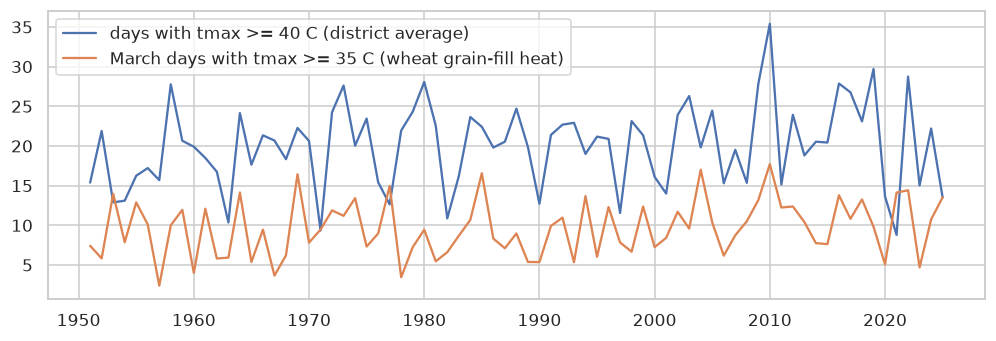

days_tmax_ge40: +0.51 days per decade (p=0.13)
march_days_tmax_ge35: +0.43 days per decade (p=0.046)


In [7]:
h = pd.read_csv(C / "national_hot_days.csv")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(h.year, h.days_tmax_ge40, label="days with tmax >= 40 C (district average)")
ax.plot(h.year, h.march_days_tmax_ge35, label="March days with tmax >= 35 C (wheat grain-fill heat)")
ax.legend(); save(fig, "09_hot_days"); plt.show()
for v in ("days_tmax_ge40", "march_days_tmax_ge35"):
    r = trend(h.year, h[v]); print(f"{v}: {r['sen_per_decade']:+.2f} days per decade (p={r['mk_p']:.2g})")

## 4. The monsoon, 1901-2025

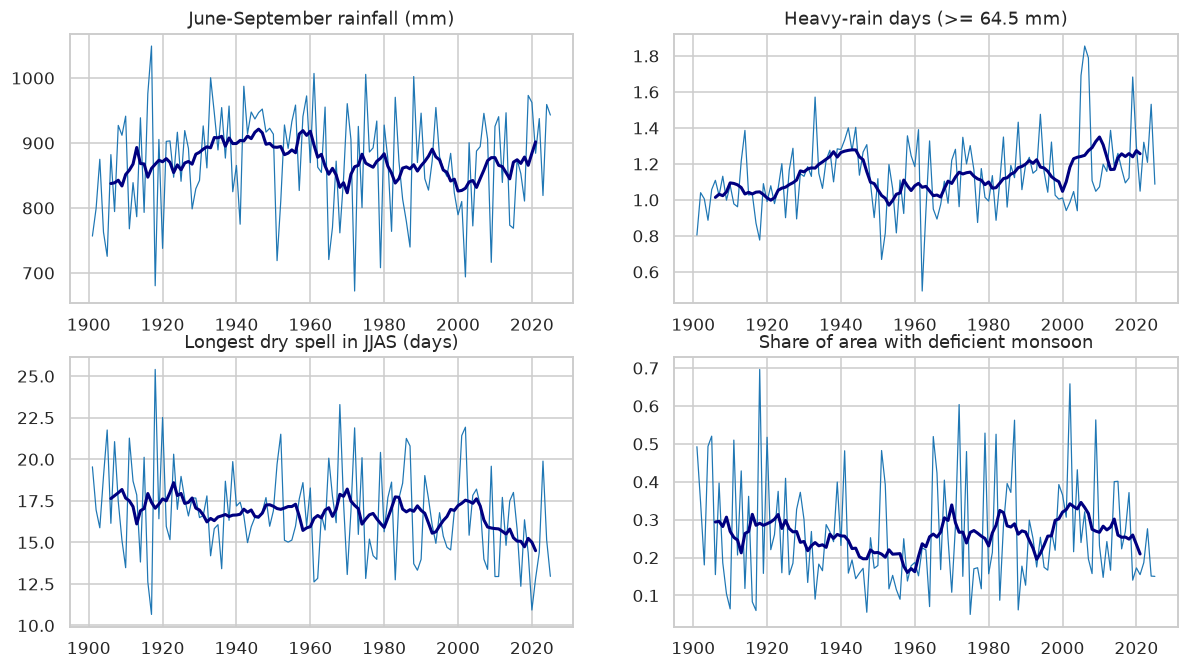

period           1901-2025  1951-2025
variable                             
annual_mm            1.471      3.407
deficient           -0.000      0.004
extreme_days         0.001      0.002
heavy_days           0.013      0.029
jjas_mm              0.909      0.857
longest_dry         -0.174     -0.271
monsoon_share        0.000     -0.001
rainy_days           0.078     -0.366
very_heavy_days      0.007      0.013

Mann-Kendall p:
period           1901-2025  1951-2025
variable                             
annual_mm            0.556      0.543
deficient            0.888      0.456
extreme_days         0.000      0.000
heavy_days           0.005      0.008
jjas_mm              0.654      0.808
longest_dry          0.013      0.097
monsoon_share        0.785      0.496
rainy_days           0.556      0.186
very_heavy_days      0.000      0.000


,decade,jjas_mm,annual_mm,rainy_days,heavy_days,very_heavy_days,extreme_days,longest_dry,deficient,monsoon_share
0,1900,826.03,1071.79,53.40,1.01,0.12,0.00,18.10,0.32,0.77
1,1910,867.65,1155.89,56.15,1.04,0.14,0.01,17.03,0.27,0.75
2,1920,858.66,1123.42,55.38,1.07,0.15,0.01,17.94,0.30,0.77
3,1930,907.87,1192.33,57.65,1.21,0.14,0.01,16.52,0.23,0.77
4,1940,916.42,1209.95,58.51,1.24,0.17,0.01,16.56,0.20,0.77
5,1950,889.30,1166.53,58.89,1.03,0.13,0.01,17.15,0.21,0.77
6,1960,851.83,1092.40,57.15,1.02,0.13,0.01,17.08,0.26,0.78
7,1970,868.93,1139.78,57.13,1.15,0.20,0.02,16.40,0.27,0.77
8,1980,861.29,1134.31,56.60,1.12,0.19,0.02,17.00,0.28,0.77
9,1990,873.92,1166.98,57.26,1.18,0.18,0.01,15.99,0.23,0.76


In [8]:
mn = pd.read_csv(C / "monsoon_national_annual.csv"); mt = pd.read_csv(C / "monsoon_national_trends.csv")
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for a, v, t in ((ax[0, 0], "jjas_mm", "June-September rainfall (mm)"), (ax[0, 1], "heavy_days", "Heavy-rain days (>= 64.5 mm)"),
                (ax[1, 0], "longest_dry", "Longest dry spell in JJAS (days)"), (ax[1, 1], "share_area_deficient", "Share of area with deficient monsoon")):
    a.plot(mn.year, mn[v], lw=.8, c="tab:blue"); a.plot(mn.year, mn[v].rolling(10, center=True).mean(), lw=2, c="navy"); a.set_title(t)
save(fig, "09_monsoon"); plt.show()
print(mt.pivot_table(index="variable", columns="period", values="sen_per_decade").round(3))
print("\nMann-Kendall p:"); print(mt.pivot_table(index="variable", columns="period", values="mk_p").round(3))
pd.read_csv(C / "monsoon_by_decade.csv").round(2)

**Reading the monsoon.** Total monsoon rain has no strong all-India trend over 125 years - the monsoon is not
simply "drying". The change is in *how* rain falls: compare heavy-rain days and dry spells in the table above. A
district average smooths out single-station cloudbursts, so heavy-day counts here are lower than station counts.

## 5. What the long-run warming means for harvests
Season night-time warming (1996-2025 normal minus 1951-1980 normal) x the robust Phase 8 night-heat coefficient.
This is a back-of-envelope number: it assumes the 1997-2022 sensitivity held earlier and ignores adaptation, new
varieties and CO2 fertilisation.

          crop  districts  season_night_warming_c_area_weighted  implied_yield_effect_pct  implied_ci_low_pct  implied_ci_high_pct  spearman_warming_rate_vs_yield_trend     p
         Wheat        443                                 0.636                    -3.352              -4.192               -2.511                                 0.159 0.001
Rice (monsoon)        574                                 0.238                    -0.312              -0.671                0.048                                -0.186 0.000


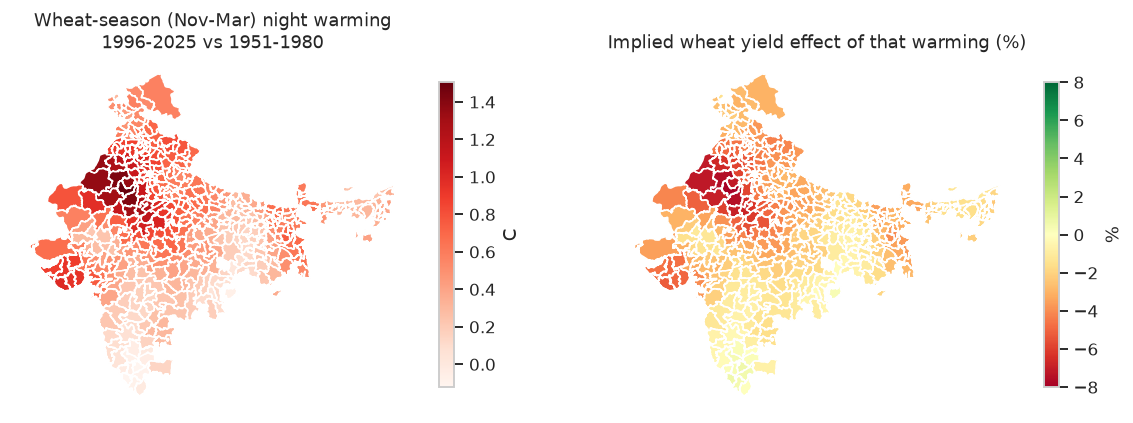

In [9]:
s = pd.read_csv(C / "harvest_link_summary.csv"); print(s.round(3).to_string(index=False))
hw = pd.read_csv(C / "harvest_link_wheat.csv")
gg = geo.merge(hw, on="district_id")
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
gg.plot(column="warming_c", cmap="Reds", legend=True, ax=ax[0], legend_kwds={"shrink": .6, "label": "C"}); ax[0].set_title("Wheat-season (Nov-Mar) night warming\n1996-2025 vs 1951-1980"); ax[0].axis("off")
gg.plot(column="implied_yield_effect_pct", cmap="RdYlGn", vmin=-8, vmax=8, legend=True, ax=ax[1], legend_kwds={"shrink": .6, "label": "%"}); ax[1].set_title("Implied wheat yield effect of that warming (%)"); ax[1].axis("off")
save(fig, "09_map_wheat_warming_impact"); plt.show()

**Reading it.** The wheat season's nights have warmed by about 0.6 C on average, which at the estimated -5% per
+1 C implies roughly a 3% (CI about 2.5-4%) drag on wheat yields compared with a 1951-80 climate - a drag that
technology and irrigation have more than offset, since yields still doubled. The district correlation between warming
rate and yield growth is weak and its sign is not causal evidence (fast-warming districts are also the irrigated
north-west where yields grew fastest).

## 6. Beyond weather: other harvest factors
Only factors available from official sources without an account could be tested (see DECISIONS D22 and
`docs/MANUAL_DOWNLOADS.md` for the rest). Skill = 1 - MSE / MSE(trend-only), on yield anomalies.
`cv_skill` = year-grouped CV inside 1997-2017 (used to judge); `test_skill` = 2018+ scored once.

In [10]:
for k in ("wheat", "rice_monsoon"):
    f = pd.read_csv(C / f"harvest_factors_{k}.csv"); print(k, "train rows", f.rows_train[0], "test rows", f.rows_test[0])
    print(f.pivot_table(index="features", columns="model", values=["cv_skill", "test_skill"]).round(3), "\n")

wheat train rows 6562 test rows 1713
                                 cv_skill               test_skill       
model                   Gradient boosting  Ridge Gradient boosting  Ridge
features                                                                 
+ both                              0.057  0.070             0.070  0.183
+ previous year's yield             0.054  0.073             0.072  0.185
+ tubewell share                   -0.018  0.021            -0.136 -0.065
weather only (v2)                  -0.016  0.024            -0.132 -0.063 

rice_monsoon train rows 7801 test rows 2102
                                 cv_skill               test_skill       
model                   Gradient boosting  Ridge Gradient boosting  Ridge
features                                                                 
+ both                              0.032  0.020             0.057  0.040
+ previous year's yield             0.030  0.020             0.057  0.039
+ tubewell share             

**Reading it.** Last year's yield anomaly is the single most useful non-weather factor: it raises wheat CV skill from
about 2% to 7%. On the test years it helps even more, partly because it corrects the drift of a trend fitted only up
to 2017 - useful for forecasting, but it is persistence, not agronomy. Groundwater dependence (tubewell share of
irrigation) adds nothing once irrigation is known. Weather still explains only a small part of year-to-year yield
changes; most variation comes from things not in public data (management, seed, pests, prices, reporting).